# 04 – Results + inspection + export for IsolationForest anomalies

Load model, score windows, inspect top anomalies, export CSV/JSON.

In [ ]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
def find_repo_root(start=None):
    """Find project root by machine_learning dir or .git/requirements.txt."""
    if start is None:
        start = Path.cwd().resolve()
    candidates = [start] + list(start.parents)
    for p in candidates:
        if (p / "machine_learning").exists():
            return p
        if (p / ".git").exists() and (p / "requirements.txt").exists():
            return p
    return start

REPO_ROOT = find_repo_root()
ML_DIR = REPO_ROOT / "machine_learning"
DATA_DIR = ML_DIR / "data"
FEATURES_DIR = ML_DIR / "features"
MODELS_DIR = ML_DIR / "models" / "isoforest"
RESULTS_DIR = ML_DIR / "results" / "isoforest"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Canonical names (match File 02 and File 03)
STRUCTURED_PATH = DATA_DIR / "processed" / "hdfs_structured.parquet"
X_PATH = FEATURES_DIR / "hdfs_window_features.npz"
ENCODER_PATH = FEATURES_DIR / "hdfs_encoder.json"
MODEL_PATH = MODELS_DIR / "isoforest.joblib"

print("REPO_ROOT      :", REPO_ROOT)
print("STRUCTURED_PATH:", STRUCTURED_PATH)
print("X_PATH         :", X_PATH)
print("ENCODER_PATH   :", ENCODER_PATH)
print("MODEL_PATH     :", MODEL_PATH)

missing = [p for p in [STRUCTURED_PATH, X_PATH, ENCODER_PATH, MODEL_PATH] if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Missing required artifact(s):\n" + "\n".join(f"- {p}" for p in missing) +
        "\n\nFix: Run File 1 (parse) + File 2 (features) + File 3 (train) to generate them."
    )

REPO_ROOT      : /Users/jay027/Desktop/github_repo/log-analysis-AI-agent
STRUCTURED_PATH: /Users/jay027/Desktop/github_repo/log-analysis-AI-agent/machine_learning/data/processed/hdfs_structured.parquet
X_PATH         : /Users/jay027/Desktop/github_repo/log-analysis-AI-agent/machine_learning/features/hdfs_window_features.npz
ENCODER_PATH   : /Users/jay027/Desktop/github_repo/log-analysis-AI-agent/machine_learning/features/hdfs_encoder.json
MODEL_PATH     : /Users/jay027/Desktop/github_repo/log-analysis-AI-agent/machine_learning/models/isoforest/isoforest.joblib


In [15]:
# ---------- Load df + features + encoder + model ----------
df = pd.read_parquet(STRUCTURED_PATH)

with open(ENCODER_PATH, "r") as f:
    enc = json.load(f)

window_size = int(enc["window_size"])
classes_ = enc["classes_"]  # index -> template_id
num_templates = len(classes_)

npz = np.load(X_PATH)
if "X" not in npz:
    raise KeyError(f"Features npz missing key 'X'. Found: {list(npz.keys())}")
X = npz["X"]

iso = joblib.load(MODEL_PATH)

print("df shape        :", df.shape)
print("X shape         :", X.shape)
print("window_size     :", window_size)
print("num templates   :", num_templates)

# Sanity checks
if X.shape[1] != num_templates:
    raise ValueError(f"X columns ({X.shape[1]}) != encoder templates ({num_templates}). Regenerate features.")

expected_windows = len(df) - window_size + 1
if X.shape[0] != expected_windows:
    raise ValueError(
        f"X windows ({X.shape[0]}) != expected ({expected_windows}) based on df rows ({len(df)}) and window_size ({window_size}).\n"
        "Fix: ensure File 2 uses the same structured parquet and window_size."
    )

df shape        : (2000, 9)
X shape         : (1981, 192)
window_size     : 20
num templates   : 192


In [16]:
# ---------- Score anomalies ----------
# sklearn: score_samples higher = more normal; invert so anomaly_score higher = more anomalous
scores = iso.score_samples(X)
anomaly_score = -scores
pred = iso.predict(X)  # -1 anomaly, 1 normal

n_anom = int(np.sum(pred == -1))
print("Anomalies detected:", n_anom, "out of", len(pred))

# Top anomaly windows by score
TOP_K = 50
top_idx = np.argsort(anomaly_score)[-TOP_K:][::-1]
top_idx[:10], anomaly_score[top_idx[:5]]

Anomalies detected: 40 out of 1981


(array([ 454,  455,  452,  453,  470,  456,  457, 1867,  473,  471]),
 array([0.45510875, 0.45305877, 0.45044888, 0.45005906, 0.44897698]))

In [17]:
# ---------- Build anomaly windows table (window -> log-row range) ----------
rows = []
for rank, wi in enumerate(top_idx, start=1):
    start = int(wi)
    end = int(wi + window_size - 1)

    start_date = df.iloc[start]["date"] if "date" in df.columns else None
    start_time = df.iloc[start]["time"] if "time" in df.columns else None
    end_date = df.iloc[end]["date"] if "date" in df.columns else None
    end_time = df.iloc[end]["time"] if "time" in df.columns else None

    rows.append({
        "rank": rank,
        "window_index": start,
        "start_row": start,
        "end_row": end,
        "start_date": None if start_date is None else str(start_date),
        "start_time": None if start_time is None else str(start_time),
        "end_date": None if end_date is None else str(end_date),
        "end_time": None if end_time is None else str(end_time),
        "anomaly_score": float(anomaly_score[wi]),
        "is_anomaly": bool(pred[wi] == -1),
    })

anom_df = pd.DataFrame(rows)
anom_df.head(10)

,rank,window_index,start_row,end_row,start_date,start_time,end_date,end_time,anomaly_score,is_anomaly
0,1,454,454,473,081110,103533,081110,103626,0.455109,True
1,2,455,455,474,081110,103534,081110,103631,0.453059,True
2,3,452,452,471,081110,103527,081110,103621,0.450449,True
3,4,453,453,472,081110,103533,081110,103621,0.450059,True
4,5,470,470,489,081110,103618,081110,103743,0.448977,True
5,6,456,456,475,081110,103538,081110,103631,0.448202,True
6,7,457,457,476,081110,103547,081110,103634,0.447960,True
7,8,1867,1867,1886,081111,090113,081111,090246,0.447762,True
8,9,473,473,492,081110,103626,081110,103801,0.445978,True
9,10,471,471,490,081110,103621,081110,103749,0.445434,True


In [18]:
# ---------- Add "what happened" summary per window (top templates) ----------
if "template_id" not in df.columns:
    raise ValueError(
        "df missing 'template_id'. Ensure File 2 saves template_id to structured parquet."
    )

tpl_map = {}
if "template" in df.columns:
    tmp = df[["template_id", "template"]].dropna().drop_duplicates()
    tpl_map = dict(zip(tmp["template_id"], tmp["template"]))

def window_top_templates(start_row, k=5):
    w = df.iloc[start_row:start_row + window_size]
    counts = w["template_id"].value_counts().head(k)
    out = []
    for tid, cnt in counts.items():
        out.append({
            "template_id": tid,
            "count": int(cnt),
            "template": tpl_map.get(tid, None)
        })
    return out

anom_df["top_templates"] = anom_df["start_row"].apply(lambda s: window_top_templates(int(s), k=5))
anom_df[["rank", "anomaly_score", "start_row", "end_row", "is_anomaly", "top_templates"]].head(10)

,rank,anomaly_score,start_row,end_row,is_anomaly,top_templates
0,1,0.455109,454,473,True,"[{'template_id': 'tpl_a931da0fda', 'count': 2,..."
1,2,0.453059,455,474,True,"[{'template_id': 'tpl_9057054aa5', 'count': 2,..."
2,3,0.450449,452,471,True,"[{'template_id': 'tpl_a931da0fda', 'count': 2,..."
3,4,0.450059,453,472,True,"[{'template_id': 'tpl_a931da0fda', 'count': 2,..."
4,5,0.448977,470,489,True,"[{'template_id': 'tpl_e09fc70470', 'count': 2,..."
5,6,0.448202,456,475,True,"[{'template_id': 'tpl_9057054aa5', 'count': 2,..."
6,7,0.447960,457,476,True,"[{'template_id': 'tpl_9057054aa5', 'count': 2,..."
7,8,0.447762,1867,1886,True,"[{'template_id': 'tpl_2a2435644c', 'count': 2,..."
8,9,0.445978,473,492,True,"[{'template_id': 'tpl_8f69677669', 'count': 2,..."
9,10,0.445434,471,490,True,"[{'template_id': 'tpl_e09fc70470', 'count': 2,..."


In [19]:
# ---------- Show raw log lines for the top anomaly window(s) ----------
TOP_SHOW = 1

display_cols = [c for c in ["date", "time", "level", "component", "message", "template_id", "template"] if c in df.columns]
for i in range(min(TOP_SHOW, len(anom_df))):
    r = anom_df.iloc[i]
    s, e = int(r["start_row"]), int(r["end_row"])
    print(f"\n=== Rank {int(r['rank'])} | score={r['anomaly_score']:.4f} | rows {s}-{e} | is_anomaly={r['is_anomaly']} ===")
    display(df.iloc[s:e+1][display_cols].head(50))


=== Rank 1 | score=0.4551 | rows 454-473 | is_anomaly=True ===


,date,time,level,component,message,template_id,template
454,081110,103533,INFO,dfs.FSDataset,Deleting block blk_-3437475890798229344 file /...,tpl_a931da0fda,Deleting block <BLK> file /mnt/hadoop/dfs/data...
455,081110,103534,INFO,dfs.FSDataset,Deleting block blk_-1492402439215451727 file /...,tpl_5da3c3d10f,Deleting block <BLK> file /mnt/hadoop/dfs/data...
456,081110,103538,INFO,dfs.FSDataset,Deleting block blk_-4298255715894292387 file /...,tpl_a9df66df5d,Deleting block <BLK> file /mnt/hadoop/dfs/data...
457,081110,103547,INFO,dfs.FSDataset,Deleting block blk_-4295805058711840933 file /...,tpl_f710b08c0b,Deleting block <BLK> file /mnt/hadoop/dfs/data...
458,081110,103548,INFO,dfs.FSDataset,Deleting block blk_830855781964014378 file /mn...,tpl_b678289f73,Deleting block <BLK> file /mnt/hadoop/dfs/data...
459,081110,103551,INFO,dfs.FSDataset,Deleting block blk_8291708741145026623 file /m...,tpl_a931da0fda,Deleting block <BLK> file /mnt/hadoop/dfs/data...
460,081110,103552,INFO,dfs.FSDataset,Deleting block blk_-921231092429668424 file /m...,tpl_43dd433526,Deleting block <BLK> file /mnt/hadoop/dfs/data...
461,081110,103553,INFO,dfs.FSDataset,Deleting block blk_-1581605246928123722 file /...,tpl_f419688859,Deleting block <BLK> file /mnt/hadoop/dfs/data...
462,081110,103554,INFO,dfs.FSDataset,Deleting block blk_-2445347158368483245 file /...,tpl_8f69677669,Deleting block <BLK> file /mnt/hadoop/dfs/data...
463,081110,103554,INFO,dfs.FSDataset,Deleting block blk_-1897524391075610396 file /...,tpl_60489c33bb,Deleting block <BLK> file /mnt/hadoop/dfs/data...


In [20]:
# ---------- Export results (CSV + JSON) ----------
csv_path = RESULTS_DIR / f"top_anomalies_w{window_size}.csv"
json_path = RESULTS_DIR / f"top_anomalies_w{window_size}.json"

anom_df_for_csv = anom_df.copy()
anom_df_for_csv["top_templates"] = anom_df_for_csv["top_templates"].apply(lambda x: json.dumps(x, ensure_ascii=False))

anom_df_for_csv.to_csv(csv_path, index=False)
anom_df.to_json(json_path, orient="records", indent=2)

print("Saved:")
print(" -", csv_path)
print(" -", json_path)

Saved:
 - /Users/jay027/Desktop/github_repo/log-analysis-AI-agent/machine_learning/results/isoforest/top_anomalies_w20.csv
 - /Users/jay027/Desktop/github_repo/log-analysis-AI-agent/machine_learning/results/isoforest/top_anomalies_w20.json


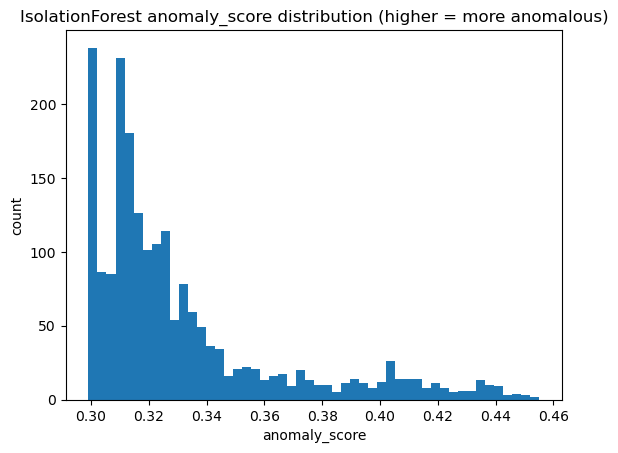

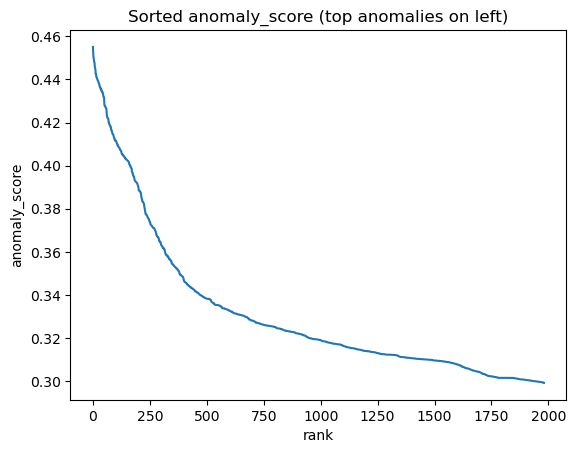

In [21]:
# ---------- (Optional) Quick visualizations ----------
plt.figure()
plt.hist(anomaly_score, bins=50)
plt.title("IsolationForest anomaly_score distribution (higher = more anomalous)")
plt.xlabel("anomaly_score")
plt.ylabel("count")
plt.show()

plt.figure()
plt.plot(np.sort(anomaly_score)[::-1])
plt.title("Sorted anomaly_score (top anomalies on left)")
plt.xlabel("rank")
plt.ylabel("anomaly_score")
plt.show()